<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and recorded source](README.md)

# 01 · A recent-PR cap changes the population behind merge time

How much does a merge-time summary depend on which pull requests we retrieve? We will read a bounded set of public `duckdb/duckdb` pull requests through the real GitHub worker, separate merged, closed-without-merge and open requests, and compare a recent subset with the full fetched sample.

**Default: recorded public API responses.** Two complete response bodies are replayed locally; they are not invented fixtures. The sample is the 200 newest PRs by creation time at acquisition, not every PR, not all work completed in a calendar window, and not a performance ranking of developers. Open PRs have not yet had an observed terminal event; their current ages are not completed merge times.

## Parameters and the proposed experiment

`RECENT_N` selects **100** or **200** PRs from the same materialized 200-row source, ordered by creation time descending and PR number descending to break ties. It models a smaller retrieval cap while holding the recorded source constant. It does not make another API call.

Change **100 → 200** to include older arrivals. Predict that the creation window will widen and the outcome mix may change; the median among observed merges need not move in a particular direction. `DATA_MODE="live"` instead makes a new bounded public request. Restart Kernel → Run All after editing.

In [1]:
RECENT_N = 100  # Accepted: 100 or 200 PRs; experiment: 200
DATA_MODE = "replay"  # "replay" or "live"; no fallback

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

from replay_source import ReplaySource

assert type(RECENT_N) is int and RECENT_N in {100, 200}
assert DATA_MODE in {"replay", "live"}
manifest = json.loads(Path("fixtures/manifest.json").read_text())
previous_api = os.environ.get("GITHUB_API_URL")
server = ReplaySource(Path("fixtures")) if DATA_MODE == "replay" else None
os.environ["GITHUB_API_URL"] = server.url if server else "https://api.github.com"
started_at = datetime.now(UTC).isoformat()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)
COLORS = {"Merged": "#17877e", "Closed without merge": "#b76e25", "Open": "#6f76b5"}


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"Source: {DATA_MODE.upper()} GitHub public API · duckdb/duckdb · observed by {AS_OF[:19]} UTC · bounded creation-ordered sample",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.07, 1, 0.97))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-github/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-github/notebooks/pyproject.toml.

## A visible, pinned connection and a bounded retrieval

The Git tag resolves to commit `d80835497330d08ccd6c3261d85061227ff85968`. `uvx` installs it independently of this checkout. The worker's SDK and transport versions are pinned to the tested protocol-3.3 runtime; Haybarn 2.0.0rc11 runs this notebook.

`auth 'off'` makes this public example anonymous in both modes. The companion redirects the worker's documented `GITHUB_API_URL` to a local replay server only in replay mode. It verifies body hashes and rewrites only pagination-link origins; the JSON responses remain unchanged. Live mode points explicitly at GitHub and never falls back to recordings.

The worker sends `state=all`, `sort=created`, `direction=desc` and `per_page=100`, then follows one `next` link to reach `max_rows=200`. A SQL `WHERE` after this call could only filter those fetched rows. [GitHub documents the listing order and pagination parameters](https://docs.github.com/en/rest/pulls/pulls#list-pull-requests).

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'github' AS github (
    TYPE vgi,
    LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-github@v0.3.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --with pyarrow==25.0.1 --with graphql-core==3.2.6 vgi-github',
    auth 'off'
);

,Success


In [4]:
%%sql
CREATE TABLE source_prs AS
SELECT repo,number,id,state,created_at,closed_at,merged_at
FROM github.main.pulls('duckdb/duckdb',state=>'all',max_rows=>200);

,Count


In [5]:
completed_at = datetime.now(UTC).isoformat()
AS_OF = manifest["entries"][-1]["completed_at_utc"] if DATA_MODE == "replay" else completed_at
source = con.execute("SELECT * FROM source_prs ORDER BY created_at DESC,number DESC").df()
fingerprint = hashlib.sha256(source.to_json(orient="records", date_format="iso").encode()).hexdigest()
assert 0 < len(source) <= 200 and source.id.is_unique and source.number.is_unique
assert source.created_at.notna().all() and set(source.state) <= {"open", "closed"}
assert source.loc[source.merged_at.notna(), "state"].eq("closed").all()
assert source.loc[source.state.eq("open"), "closed_at"].isna().all()
assert source.loc[source.state.eq("closed"), "closed_at"].notna().all()
assert ((source.closed_at - source.created_at).dropna().dt.total_seconds() >= 0).all()
assert ((source.merged_at - source.created_at).dropna().dt.total_seconds() >= 0).all()
assert source.created_at.le(pd.Timestamp(AS_OF)).all()
if server:
    expected = [
        r for e in manifest["entries"] for r in json.loads((Path("fixtures") / e["filename"]).read_bytes())
    ]
    assert set(source.id) == {r["id"] for r in expected}
    assert len(server.requests) == 2
    display(
        pd.DataFrame(
            [
                {k: e[k] for k in ["page", "rows", "started_at_utc", "completed_at_utc", "sha256"]}
                for e in manifest["entries"]
            ]
        )
    )
prose(
    f"**{DATA_MODE.upper()} · {len(source):,} distinct PRs materialized once.** Observation clock: `{AS_OF}`. Returned-source fingerprint: `{fingerprint}`. Acquisition covered two separately requested pages; it was not an atomic repository snapshot. A finite cap can omit older open PRs and older PRs merged recently."
)

,page,rows,started_at_utc,completed_at_utc,sha256
0,1,100,2026-11-14T06:55:37.197060+00:00,2026-11-14T06:55:38.130965+00:00,7eeed64aed6bb5d3a4311e4ef27b68a674d6f241cbd844...
1,2,100,2026-11-14T06:55:38.144987+00:00,2026-11-14T06:55:39.864399+00:00,07be24022dc09ad510025fc87495d59a2035715a0bf9f9...


**REPLAY · 200 distinct PRs materialized once.** Observation clock: `2026-11-14T06:55:39.864399+00:00`. Returned-source fingerprint: `39592f783d26722c404fe5b1679447a791b3bbb6e4dafeca86afef0e8386dfa6`. Acquisition covered two separately requested pages; it was not an atomic repository snapshot. A finite cap can omit older open PRs and older PRs merged recently.

## Classify outcomes before calculating durations

A merged PR is identified by non-NULL `merged_at`, not merely `state='closed'`. We keep three disjoint outcomes. For merged PRs, elapsed days run from creation to merge. For closed-without-merge PRs, they run to closure. For open PRs, they run only to the observation clock and remain unfinished ages. All timestamps are UTC; fractional days are seconds divided by 86,400.

The smaller subset uses a local row-number cap on the fixed source. Unlike asking GitHub for only closed PRs, this does not exclude open arrivals before selecting the population.

In [6]:
%%sql
CREATE TABLE classified AS
SELECT *,
       CASE WHEN merged_at IS NOT NULL THEN 'Merged'
            WHEN state='closed' THEN 'Closed without merge'
            ELSE 'Open' END AS outcome,
       epoch(coalesce(merged_at,closed_at,TIMESTAMPTZ '{{AS_OF}}')-created_at)/86400.0 AS elapsed_days,
       row_number() OVER (ORDER BY created_at DESC,number DESC) AS recent_rank
FROM source_prs;
CREATE TABLE selected AS SELECT * FROM classified WHERE recent_rank<={{RECENT_N}};

,Count


In [7]:
%%sql populations <<
WITH cohorts AS (
  SELECT 'Selected recent subset' AS population,* FROM selected
  UNION ALL
  SELECT 'All fetched PRs',* FROM classified
)
SELECT population,outcome,count(*) AS prs,
       min(created_at) AS first_created_utc,max(created_at) AS last_created_utc,
       median(elapsed_days) AS median_elapsed_days
FROM cohorts GROUP BY population,outcome ORDER BY population,outcome;

In [8]:
display(populations)
selected = con.execute("SELECT * FROM selected ORDER BY recent_rank").df()
assert len(selected) == min(RECENT_N, len(source))
assert selected.elapsed_days.notna().all() and selected.elapsed_days.ge(0).all()
assert populations.groupby("population").prs.sum().to_dict() == {
    "All fetched PRs": len(source),
    "Selected recent subset": len(selected),
}
first = selected.created_at.min()
last = selected.created_at.max()
prose(
    f"The selected **{len(selected)} PRs** were created from **{first:%Y-%m-%d %H:%M} to {last:%Y-%m-%d %H:%M} UTC** (observed min/max, both included). The full fetched sample starts at **{source.created_at.min():%Y-%m-%d %H:%M} UTC**. These are creation windows, not merge windows; records can remain open beyond them."
)

,population,outcome,prs,first_created_utc,last_created_utc,median_elapsed_days
0,All fetched PRs,Closed without merge,18,2026-11-10 03:07:53-05:00,2026-11-13 06:54:24-05:00,0.077378
1,All fetched PRs,Merged,90,2026-11-09 12:57:18-05:00,2026-11-13 08:27:52-05:00,0.750590
2,All fetched PRs,Open,92,2026-11-09 16:14:07-05:00,2026-11-13 19:54:39-05:00,1.637811
3,Selected recent subset,Closed without merge,6,2026-11-11 16:34:08-05:00,2026-11-13 06:54:24-05:00,0.038524
4,Selected recent subset,Merged,31,2026-11-11 15:00:32-05:00,2026-11-13 08:27:52-05:00,0.329907
5,Selected recent subset,Open,63,2026-11-11 15:17:28-05:00,2026-11-13 19:54:39-05:00,0.887811


The selected **100 PRs** were created from **2026-11-11 15:00 to 2026-11-13 19:54 UTC** (observed min/max, both included). The full fetched sample starts at **2026-11-09 12:57 UTC**. These are creation windows, not merge windows; records can remain open beyond them.

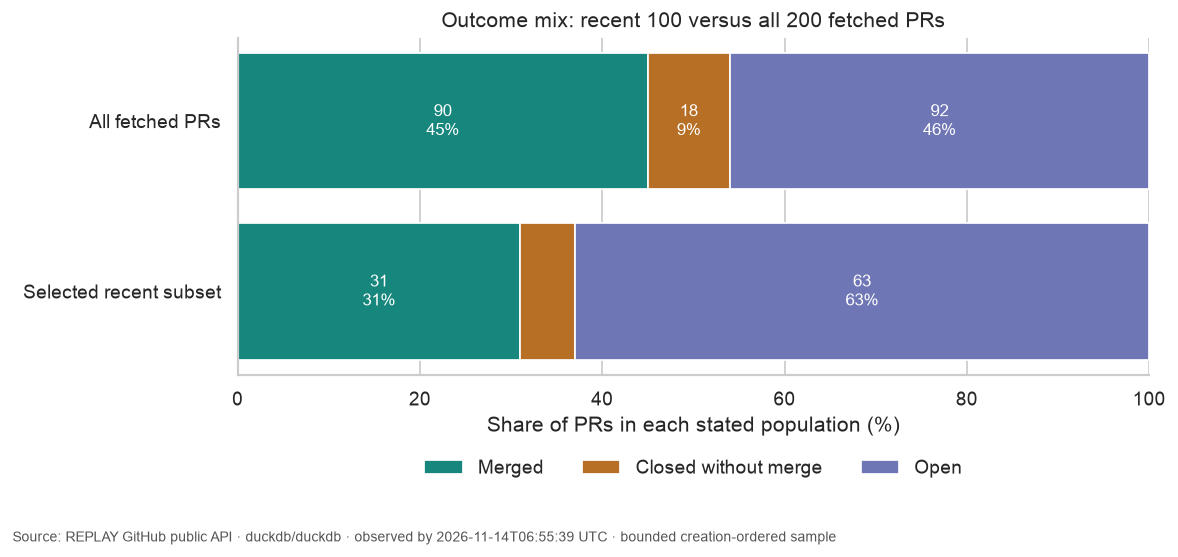

In [9]:
order = list(COLORS)
pivot = (
    populations.pivot(index="population", columns="outcome", values="prs")
    .reindex(index=["Selected recent subset", "All fetched PRs"], columns=order)
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(9.5, 4.6))
left = np.zeros(len(pivot))
for outcome in order:
    shares = pivot[outcome].to_numpy() / pivot.sum(axis=1).to_numpy() * 100
    ax.barh(pivot.index, shares, left=left, color=COLORS[outcome], label=outcome)
    for i, (count, width, start) in enumerate(zip(pivot[outcome], shares, left, strict=True)):
        if width >= 7:
            ax.text(
                start + width / 2,
                i,
                f"{int(count)}\n{width:.0f}%",
                ha="center",
                va="center",
                color="white",
                fontsize=10,
            )
    left += shares
ax.set(
    xlabel="Share of PRs in each stated population (%)",
    xlim=(0, 100),
    title=f"Outcome mix: recent {len(selected)} versus all {len(source)} fetched PRs",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=3, frameon=False)
fig.subplots_adjust(bottom=0.30)
finish(fig)

## Keep unfinished ages separate from completed merge times

The next query computes a descriptive median only for observed merges. It also reports how many selected PRs were still open and how many closed without merging. Dropping these groups silently would change the denominator. Closed-without-merge is a distinct terminal outcome, not a zero-day merge.

The three panels show different elapsed-time meanings on a shared day scale. Each curve is an empirical cumulative distribution within its outcome and population. Open-age curves are not survival curves or predictions of eventual merge time. Recent arrival selection and unfinished observations prevent these medians from estimating the lifetime merge-time distribution.

In [10]:
%%sql comparison <<
WITH cohorts AS (
 SELECT 'Selected recent subset' AS population,* FROM selected
 UNION ALL SELECT 'All fetched PRs',* FROM classified
)
SELECT population,count(*) AS prs,
 count(*) FILTER (WHERE outcome='Merged') AS merged,
 count(*) FILTER (WHERE outcome='Open') AS still_open,
 count(*) FILTER (WHERE outcome='Closed without merge') AS closed_unmerged,
 median(elapsed_days) FILTER (WHERE outcome='Merged') AS median_merge_days
FROM cohorts GROUP BY population ORDER BY population;

In [11]:
display(comparison)
assert (comparison.prs == comparison.merged + comparison.still_open + comparison.closed_unmerged).all()
a = comparison.set_index("population").loc["Selected recent subset"]
b = comparison.set_index("population").loc["All fetched PRs"]


def days(value):
    return "unavailable (no observed merges)" if pd.isna(value) else f"{value:.2f} days"


prose(
    f"Among selected PRs, **{int(a.merged)} merged**, **{int(a.closed_unmerged)} closed without merging**, and **{int(a.still_open)} remain open**. The median creation-to-merge time is **{days(a.median_merge_days)}**, conditional on those observed merges; for all fetched PRs it is **{days(b.median_merge_days)}**. This comparison changes the arrival population, not the project's underlying process in a controlled experiment."
)

,population,prs,merged,still_open,closed_unmerged,median_merge_days
0,All fetched PRs,200,90,92,18,0.750590
1,Selected recent subset,100,31,63,6,0.329907


Among selected PRs, **31 merged**, **6 closed without merging**, and **63 remain open**. The median creation-to-merge time is **0.33 days**, conditional on those observed merges; for all fetched PRs it is **0.75 days**. This comparison changes the arrival population, not the project's underlying process in a controlled experiment.

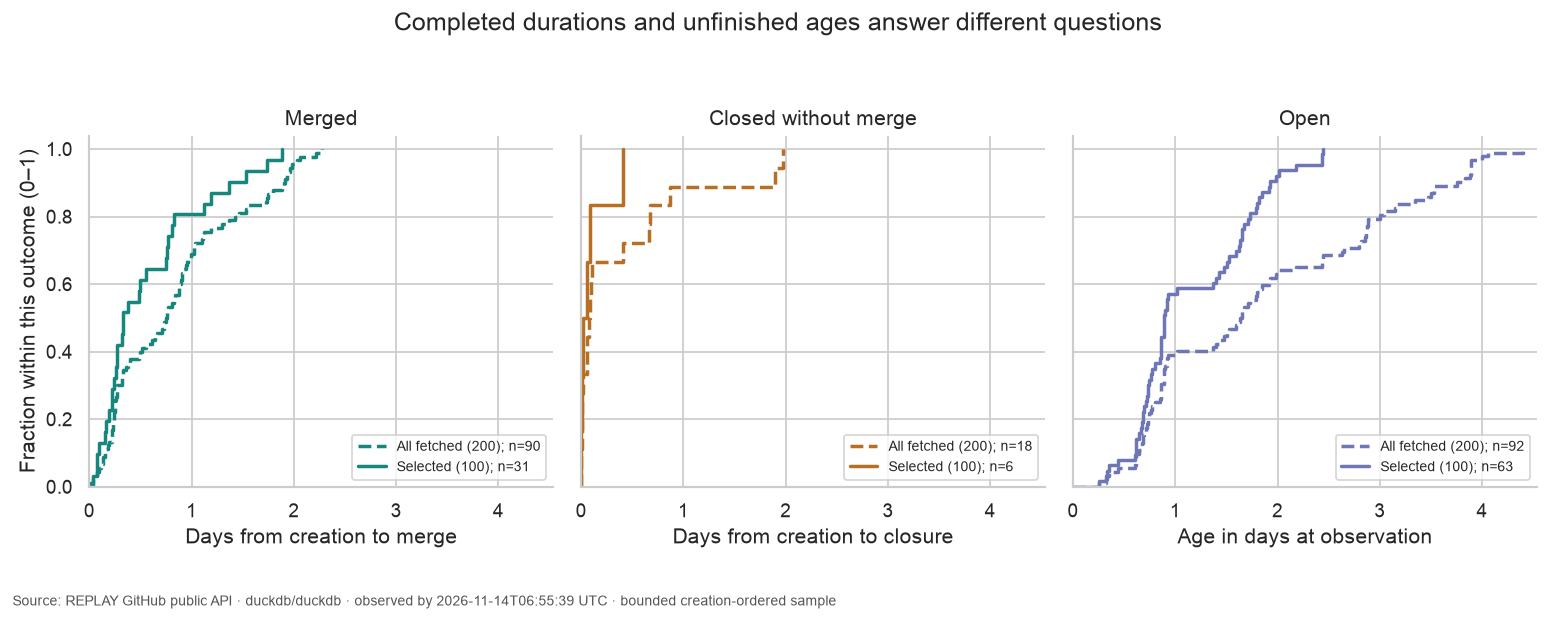

In [12]:
all_rows = con.execute("SELECT * FROM classified ORDER BY recent_rank").df()
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.7), sharex=True, sharey=True)
for ax, outcome in zip(axes, COLORS, strict=True):
    for frame, label, style in [
        (all_rows, f"All fetched ({len(source)})", "--"),
        (selected, f"Selected ({len(selected)})", "-"),
    ]:
        x = np.sort(frame.loc[frame.outcome.eq(outcome), "elapsed_days"].to_numpy())
        if len(x):
            ax.step(
                np.r_[0, x],
                np.r_[0, np.arange(1, len(x) + 1) / len(x)],
                where="post",
                color=COLORS[outcome],
                linestyle=style,
                label=f"{label}; n={len(x)}",
                lw=2,
            )
        else:
            ax.plot([], [], color=COLORS[outcome], linestyle=style, label=f"{label}; no observations")
    ax.set(
        title=outcome,
        xlabel={
            "Merged": "Days from creation to merge",
            "Closed without merge": "Days from creation to closure",
            "Open": "Age in days at observation",
        }[outcome],
        ylim=(0, 1.04),
        xlim=(0, max(1, all_rows.elapsed_days.max() * 1.03)),
    )
    ax.legend(loc="lower right", fontsize=8, frameon=True)
axes[0].set_ylabel("Fraction within this outcome (0–1)")
fig.suptitle("Completed durations and unfinished ages answer different questions", y=1.02)
finish(fig)

## Experiment: widen the same recorded population

Change only `RECENT_N` from **100 to 200**, rerun in a separate output directory and compare the creation boundary, outcome counts and conditional merge median. At 200, the selected and full-sample curves should coincide. The materialized-source fingerprint must remain unchanged in replay mode. Restore **100** afterwards.

An older sample may contain more completed outcomes simply because it has had more time to finish. That does not establish an improvement or slowdown. Neither this sample nor the two-page API acquisition proves repository-wide completeness. To answer a calendar-cohort or lifetime question, design an explicit arrival cohort, observation horizon and treatment of unfinished and competing outcomes first.

In [13]:
con.close()
if server:
    server.close()
if previous_api is None:
    os.environ.pop("GITHUB_API_URL", None)
else:
    os.environ["GITHUB_API_URL"] = previous_api

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)